### What are Multi-Agent RAG Systems?
A Multi-Agent RAG System splits the RAG pipeline into multiple specialized agents — each responsible for a specific role — and enables them to collaborate on a single query or task.

#### 1. Multi-Agent Network RAG System with LangGraph
Project Overview

A beginner-friendly Retrieval-Augmented Generation (RAG) system that uses a multi-agent architecture to intelligently answer questions from your documents. Built with LangGraph v0.3 for workflow orchestration and OpenAI for language understanding.

What It Does

Transforms your documents (PDFs, text files) into a searchable knowledge base that can answer questions intelligently using AI. Simply upload documents and ask questions in natural language - the system finds relevant information and generates comprehensive answers.
Key Features

- 📚 Multi-Format Support: Handles PDF and text documents
- 🤖 3-Agent Architecture: Specialized agents for document processing, retrieval, and answer generation
- 🔍 Smart Search: Vector-based semantic search finds relevant information
- 💬 Natural Language Q&A: Ask questions in plain English

#### Hierarchical Agent Teams With RAG System

the concept of a single supervisor node to route work between different worker nodes.

In [111]:
import os
from dotenv import load_dotenv

In [2]:
##Laod Environment
load_dotenv()

## set up the environment
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

In [ ]:
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter

/var/folders/6c/rlq9mq415gbd8q7dxvzdt3zr0000gn/T/ipykernel_1775/2926337271.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [4]:
## Initiate model
llm=init_chat_model("openai:gpt-4o-mini")

In [18]:
from typing import Annotated
from langchain_core.tools import tool, Tool
from langchain_tavily import TavilySearch

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper


In [11]:
tavily_tool = TavilySearch(max_results=3)

In [103]:
from langchain_community.document_loaders import WebBaseLoader, TextLoader

def make_retriever_tool_from_text(file,name,desc):
    docs=TextLoader(file,encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    vs = FAISS.from_documents(chunks, OpenAIEmbeddings())
    retriever = vs.as_retriever()

    def tool_func(query:str)->str:
        print(f"📚 Using tool: {name}")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results)
    
    return Tool(name=name,description=desc,func=tool_func)


internal_tool_1=make_retriever_tool_from_text("internal_docs.txt",
                                              "InternalResearchNotes",
                                              "Climate change disrupts ecosystems across the planet")


In [68]:
from typing import List

@tool
def scrap_webpages(url: List[str]) -> str:
    """
    Scraps the content of the given webpages and returns the text.
    """
    loader = WebBaseLoader(url)
    docs = loader.load()
    return "\n\n".join([
        f'<document name="{doc.metadata.get("title", "")}">\n{doc.page_content}\n</document>' for doc in docs
    ])

In [66]:
from pathlib import Path
from tempfile import TemporaryDirectory
from typing import Dict, Optional

from langchain_experimental.utilities import PythonREPL
from typing_extensions import TypedDict

_TEMP_DIRECTORY = TemporaryDirectory()
WORKING_DIRECTORY = Path(_TEMP_DIRECTORY.name)




In [67]:

from langgraph.graph import END, START, StateGraph, MessagesState
from typing import List, Optional, Literal
from langgraph.types import Command
from langchain_core.messages import HumanMessage, trim_messages

class State(MessagesState):
    next: str
    

In [70]:
from typing import Literal, TypedDict

from langchain_core.language_models import BaseChatModel


def make_supervisior_node(llm: BaseChatModel, members: list[str]) -> str:
    options = ["FINISH"] + members
    system_prompt = (
        "You are a supervisor tasked with manageing a conversation between the"
        f" following workers: {members}. Given the following user request,"
        " you should decide which worker is best suited to handle the request."
        " respond with their result and status. When finished"
        " respond with FINISH."
    )

    class Router(TypedDict):
        """Worker to route to next. If no worker needed, route to FINISH."""

        next: Literal[*options]

    def supervisor_node(state: State) -> Command[Literal[*members, "__end__"]]:
        """An LLM-based router."""
        messages = [
            {"role": "system", "content": system_prompt},
        ] + state["messages"]
        response = llm.with_structured_output(Router).invoke(messages)
        goto  = response["next"]
        if goto == "Finish":
            goto = END
        return Command(goto=goto, update={"next": goto})

    return supervisor_node

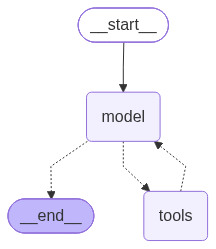

In [104]:
#Create Agent

from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent

search_agent = create_agent(llm, tools=[tavily_tool, internal_tool_1])

search_agent


In [105]:
def search_node(state: State) -> Command[Literal["supervisor"]]:
    result = search_agent.invoke(state)

    return Command(
        update={
            "messages":[
                HumanMessage(content=result["messages"][-1].content, name="search")
            ]
        },
        # We want our worker report back to supervisor node when done
        goto="supervisor"
    )

In [89]:
research_supervisor_node = make_supervisior_node(llm, ["search", "web_scraper"])

### sub agent
web_scraper_agent = create_agent(llm, tools=[scrap_webpages])


def web_scraper_node(state: State) -> Command[Literal["supervisor"]]:
    result = web_scraper_agent.invoke(state)
    return Command(
        update={
            "messages": [
                HumanMessage(content=result["messages"][-1].content, name="web_scraper")
            ]
        },
        # We want our workers to ALWAYS "report back" to the supervisor when done
        goto="supervisor",
    )

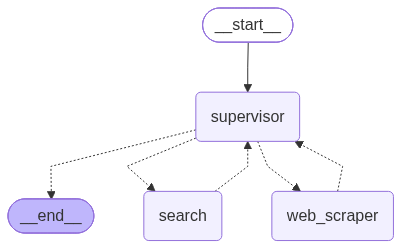

In [106]:
research_builder = StateGraph(State)
research_builder.add_node("supervisor", research_supervisor_node)
research_builder.add_node("search", search_node)
research_builder.add_node("web_scraper", web_scraper_node)

research_builder.add_edge(START, "supervisor")
research_graph = research_builder.compile()
research_graph

In [90]:
@tool
def read_document(
    filename: Annotated[str, "File path to read."],
    start: Annotated[Optional[int], "Start the line, default is 0"] = None,
    end: Annotated[Optional[int], "End the line, default is None"] = None
) -> Annotated[str, "Content of the read document."]:
    """
    Reads the content of a document.
    """
    with (WORKING_DIRECTORY / filename).open("r") as file:
        lines = file.readlines()
    if start is None:
        start = 0

    return "\n".join(lines[start:end])

In [91]:
@tool
def write_document(
    content: Annotated[str, "Content to write to the document."],
    filename: Annotated[str, "File path to save the document."]
) -> Annotated[str, "Path of the saved document file."]:
    """
    Creates and saves a document.
    """
    with (WORKING_DIRECTORY / filename).open("w") as f:
        f.write(content)
    return f"Document saved to {filename}"

@tool
def edit_document(
    filename: Annotated[str, "File path to save the document."],
    inserted_content: Annotated[Dict[int, str], "Dictionary where keys are line numbers and values are the content to insert at those lines."]
) -> Annotated[str, "Path of the saved document file."]:
    """
    Creates and saves a document.
    """
    with (WORKING_DIRECTORY / filename).open("r") as f:
        lines = f.readlines()

    sorted_content = sorted(inserted_content.items())

    for line_num, content in sorted_content:
        if 1 <= line_num < len(lines)+1:
            lines[line_num-1] = content + "\n"
        else:
            return f"Line number {line_num} is out of range for the document."
        
    with (WORKING_DIRECTORY / filename).open("w") as f:
        f.writelines(lines)
        
    return f"Document saved to {filename}"

doc_writer_agent = create_agent(
    llm, 
    tools=[write_document, edit_document, read_document],
    system_prompt="You are a document writer agent. You can write, edit and read documents. Use the tools provided to you to perform these actions."
)

def doc_writer_node(state: State) -> Command[Literal["supervisor"]]:
    result = doc_writer_agent.invoke(state)
    return Command(
        update={
            "messages": [
                HumanMessage(content=result["messages"][-1].content, name="doc_writer")
            ]
        },
        # We want our workers to ALWAYS "report back" to the supervisor when done
        goto="supervisor",
    )


In [92]:
# Create outline

@tool
def create_outline(
    points: Annotated[List[str], "List of main points or sections outline."],
    filename: Annotated[str, "File path to save the outline."]
) -> Annotated[str, "Path of the saved outline file."]:
    """
    Creates and saves an outline.
    """
    with (WORKING_DIRECTORY / filename).open("w") as f:
        for i, point in enumerate(points):
            f.write(f"{i+1}, {point}\n")
        return f"Outline saved to {filename}"
    
note_taking_agent = create_agent(
    llm,
    tools=[create_outline, read_document],
    system_prompt="You are a note taking agent. You can create outlines and read documents. Use the tools provided to you to perform these actions."
)

def note_taking_node(state: State) -> Command[Literal["supervisor"]]:
    result = note_taking_agent.invoke(state)
    return Command(
        update={
            "messages": [
                HumanMessage(content=result["messages"][-1].content, name="note_taking")
            ]
        },
        # We want our workers to ALWAYS "report back" to the supervisor when done
        goto="supervisor",
    )

In [ ]:
repl = PythonREPL()

@tool
def python_repl_tool(
    code: Annotated[str, "Python code to execute in the REPL environment."]
):
    """Use this to execute python code. If you want to see the output of value,
    You should print it our with `print(...)`, this is visible to the user. """

    try:
        result = repl.run(code)
    except BaseException as e:
        return f"Error executing code: {repr(e)}"
    return f"Successfully executed code. \n ```python\n{code}\n``` \nResult: {result}"

chart_generating_agent = create_agent(
    llm,
    tools=[read_document, python_repl_tool],
    system_prompt="You are a chart generating agent. You can read documents and execute python code"
)

def chart_generating_node(state: State) -> Command[Literal["supervisor"]]:
    result = chart_generating_agent.invoke(state)
    return Command(
        update={
            "messages": [
                HumanMessage(content=result["messages" \
                ""][-1].content, name="chart_generating")
            ]
        },
        # We want our workers to ALWAYS "report back" to the supervisor when done
        goto="supervisor",
    )
writing_supervisor_node = make_supervisior_node(llm, ["doc_writer", "note_taking", "chart_generating"])


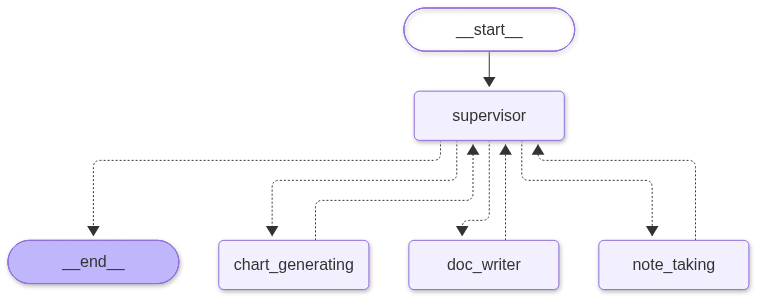

In [94]:
writing_builder = StateGraph(State)
writing_builder.add_node("supervisor", writing_supervisor_node)
writing_builder.add_node("doc_writer", doc_writer_node)
writing_builder.add_node("note_taking", note_taking_node)
writing_builder.add_node("chart_generating", chart_generating_node)

writing_builder.add_edge(START, "supervisor")
writing_graph = writing_builder.compile()
writing_graph

In [95]:
teams_supervisor_node = make_supervisior_node(llm, ["research_team", "writing_team"])
teams_supervisor_node

<function __main__.make_supervisior_node.<locals>.supervisor_node(state: __main__.State) -> langgraph.types.Command[typing.Literal['research_team', 'writing_team', '__end__']]>

In [107]:
def call_writing_team(state: State) -> Command[Literal["supervisor"]]:
    result = writing_graph.invoke(state)
    return Command(
        update={
            "messages": [
                HumanMessage(content=result["messages"][-1].content, name="writing_team")
            ]
        },
        # We want our workers to ALWAYS "report back" to the supervisor when done
        goto="supervisor",
    )

def call_research_team(state: State) -> Command[Literal["supervisor"]]:
    result = research_graph.invoke(state)
    return Command(
        update={
            "messages": [
                HumanMessage(content=result["messages"][-1].content, name="research_team")
            ]
        },
        # We want our workers to ALWAYS "report back" to the supervisor when done
        goto="supervisor",
    )

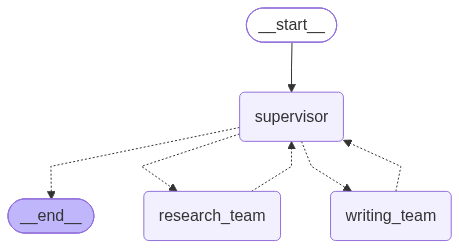

In [108]:
super_builder = StateGraph(State)
super_builder.add_node("supervisor", teams_supervisor_node)
super_builder.add_node("research_team", call_research_team)
super_builder.add_node("writing_team", call_writing_team)

super_builder.add_edge(START, "supervisor")
super_graph = super_builder.compile()
super_graph

In [109]:
response = super_graph.invoke(
    {
        "messages": [
            ("user", "I want to write a research paper on the effects of climate change on polar bears.")
        ]
    }
)



Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel branch:to:FINISH, ignoring it.
Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel branch:to:FINISH, ignoring it.
Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel branch:to:FINISH, ignoring it.
Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel branch:to:FINISH, ignoring it.


In [110]:
response

{'messages': [HumanMessage(content='I want to write a research paper on the effects of climate change on polar bears.', additional_kwargs={}, response_metadata={}, id='f021b917-b86c-44e8-8d7f-afd91338e9d3'),
  HumanMessage(content="Let's start with an outline. Here’s a suggested structure for your research paper on the effects of climate change on polar bears:\n\n### Outline for Research Paper on Polar Bears and Climate Change\n\n1. **Introduction**\n   - Background on polar bears\n   - Importance of studying climate change effects\n   - Purpose of the research paper\n\n2. **Overview of Climate Change**\n   - Definition and causes of climate change\n   - Current trends and projections\n   - General effects on wildlife\n\n3. **Polar Bears: Biology and Habitat**\n   - Description and characteristics of polar bears\n   - Natural habitat and range\n   - Ecological role in the Arctic ecosystem\n\n4. **Impact of Climate Change on Polar Bears**\n   - Melting sea ice and its implications\n   -